# 04 - Object-only and background-only accuracy

If you ran notebook 03, you now have the predictions of every model on the original images, the object-only images, the background-only images and the composites. Before we get to the composites, we look at the simpler cases.

How well do models recognise an object when its background is gone? And how often do they still guess the right class when only the background is left? Comparing both with the accuracy on the original images tells us how much the object and the background each contribute to recognition. At the end, we look at what the models predict when they get a background-only image wrong.

In [1]:
from pathlib import Path

# Repository paths
REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Prediction CSVs from notebook 03 and the semantic axis from notebook 01
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
SIMILARITY_MATRIX = DATA_DIR / "semantic_axes" / "consensus.npy"

# Background categories of the main set and the class names, for the last section
METADATA = REPO_ROOT / "ImageNet-OOC1k" / "source" / "metadata.csv"
CLASS_INDEX = REPO_ROOT / "helper_files" / "imagenet_class_index.json"

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Plotting functions live outside the notebook to keep it readable.
from ooc1k.plotting.c_controls import plot_background_only, plot_controls_overview, plot_error_ranks, plot_error_structure, plot_object_only, plot_top5_ranks

## Models and settings

`MODELS` selects which models all cells below use. `MAIN_MODELS` are the six models shown in the main figures of the paper. `ALL_MODELS` are all models that have background-only predictions in `PREDICTIONS_DIR`, so all 35 if you ran notebook 03 with `ALL_MODELS`.

`TOP_K` sets the accuracy measure. The main figures of the paper use top-1. Set it to 5 to see how often the correct class is at least among the five best guesses.

In [3]:
MAIN_MODELS = ["ViT-B-16", "ViT-L-16", "DeiT-B-16", "ResNet-50", "EfficientNet-B3", "CLIP-ViT-B-16"]
ALL_MODELS = sorted({path.name.split("_background_only_")[0] for path in PREDICTIONS_DIR.glob("*_background_only_*.csv")})

MODELS = MAIN_MODELS        # or ALL_MODELS
MODELS = ALL_MODELS
TOP_K = 5                   # try 5
OBJECT_BACKGROUNDS = ["black", "white", "pink_noise"]
NEIGHBORHOOD = 25           # number of nearest semantic neighbours we look at in the last section

print(f"Using {len(MODELS)} of {len(ALL_MODELS)} models with predictions in {PREDICTIONS_DIR}")

Using 35 of 35 models with predictions in /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/outputs/predictions


## Scoring the predictions

Every prediction CSV holds one row per image, with the true class and the model's five best guesses. An image counts as correct if the true class is among the first `TOP_K` guesses.

For every model, we score the original images, the object-only images on each of the three backgrounds (and their mean), and the background-only images. All of them come from the same images of the main set, so the accuracies are directly comparable.

In [4]:
def load_predictions(model, condition):
    """Load the newest prediction CSV of a model for one image condition."""
    csv_path = sorted(PREDICTIONS_DIR.glob(f"{model}_{condition}_*.csv"))[-1]
    return pd.read_csv(csv_path)


def get_accuracy(model, condition, top_k):
    """Fraction of images whose true class is among the first top_k predictions."""
    predictions = load_predictions(model, condition)
    guesses = predictions["top5_indices"].apply(json.loads)
    return np.mean([true_class in top[:top_k] for true_class, top in zip(predictions["true_class_idx"], guesses)])


def get_accuracy_table(models, top_k):
    """Accuracy of every model on the original, object-only and background-only images."""
    rows = {}
    for model in models:
        row = {"original": get_accuracy(model, "original_main", top_k)}
        for background in OBJECT_BACKGROUNDS:
            row[background] = get_accuracy(model, f"object_main_{background}", top_k)
        row["object_only"] = np.mean([row[background] for background in OBJECT_BACKGROUNDS])
        row["background_only"] = get_accuracy(model, "background_only", top_k)
        rows[model] = row
    return pd.DataFrame.from_dict(rows, orient="index")

In [5]:
accuracy = get_accuracy_table(MODELS, TOP_K)

# The plots always order the models by their top-1 accuracy, so top-1 and top-5 plots show the same order.
order = get_accuracy_table(MODELS, top_k=1)

# Accuracy in percent
(100 * accuracy).round(1)

,original,black,white,pink_noise,object_only,background_only
CLIP-ViT-B-16,88.2,77.2,78.6,75.2,77.0,15.5
DeiT-B-16,95.2,82.8,85.8,78.1,82.2,33.0
EfficientNet-B3,94.6,83.9,86.2,79.2,83.1,23.7
ResNet-50,93.1,79.9,84.1,78.0,80.7,27.4
ViT-B-16,97.4,86.7,89.2,85.0,87.0,34.0
ViT-L-16,97.2,87.2,87.6,84.4,86.4,35.4
beit3_base_patch16_224,96.7,87.0,88.3,81.0,85.4,33.0
beit3_large_patch16_224,97.6,89.4,88.9,84.9,87.7,36.9
beit_base_patch16_224,97.1,85.6,88.4,83.2,85.7,30.3
beit_large_patch16_224,97.5,89.4,91.1,87.7,89.4,36.3


## Object-only accuracy

First, we take the background away and only show the object, on black, white and pink noise. The dashed lines show the accuracy on the original images.

Accuracy drops, but most objects are still recognised. So the models mostly rely on the object itself, but they do benefit from its context. Which neutral background the object is shown on hardly matters.

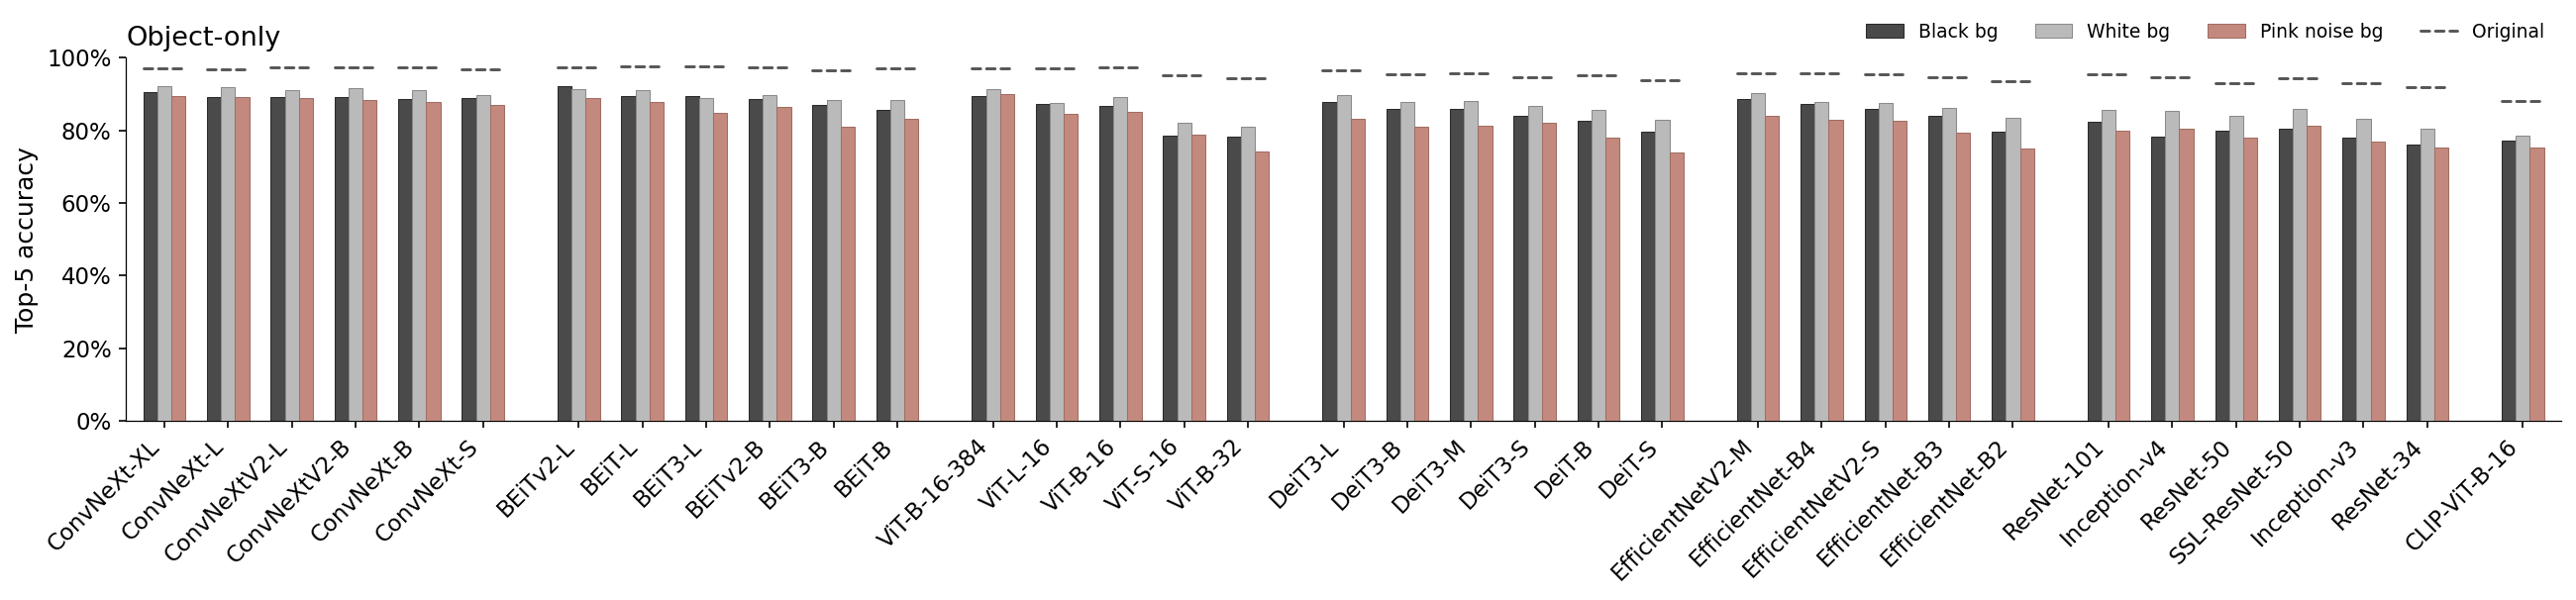

Drop compared to the original images: 6.3 to 16.6 percentage points


In [6]:
fig = plot_object_only(accuracy, TOP_K, order=order)
fig.savefig(FIG_DIR / "object_only.pdf")
plt.show()

drop = accuracy["original"] - accuracy["object_only"]
print(f"Drop compared to the original images: {100 * drop.min():.1f} to {100 * drop.max():.1f} percentage points")

## Background-only accuracy

Now the other way round: we remove the object and only show the inpainted background. Guessing randomly among the 1,000 ImageNet classes would give 0.1% top-1 accuracy.

The models are of course much worse than with the object, but still far above chance. The background alone carries information about the class of the object that used to be in it. Try `TOP_K = 5` in the settings above: the correct class is quite often among the five best guesses, even without the object.

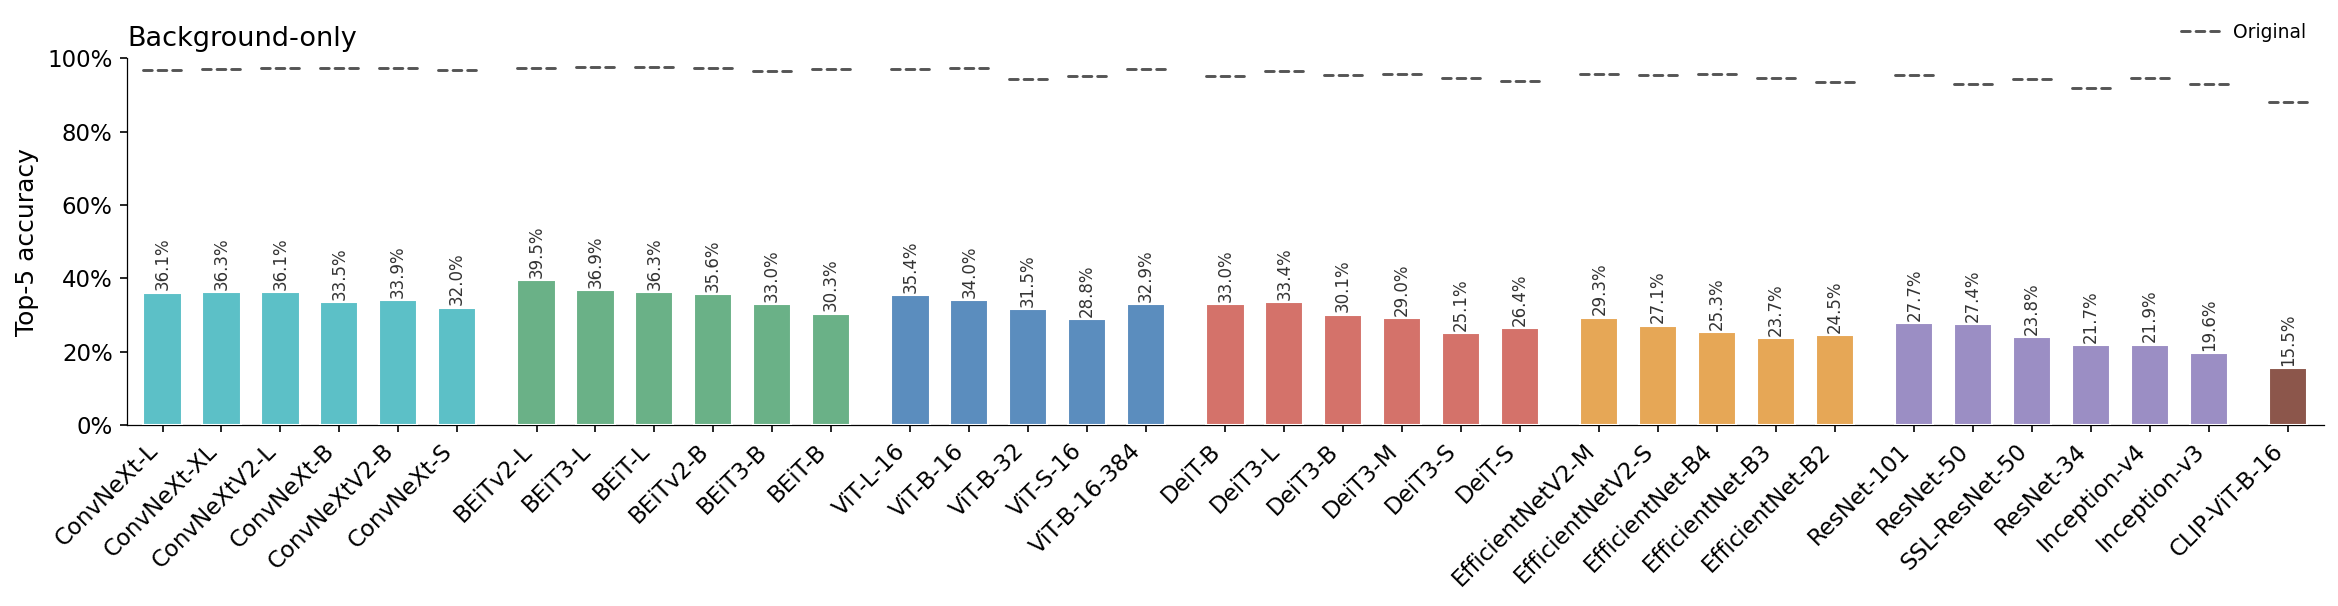

Mean background-only accuracy: 29.9% (chance: 0.5%)


In [7]:
fig = plot_background_only(accuracy, TOP_K, order=order)
fig.savefig(FIG_DIR / "background_only.pdf")
plt.show()

print(f"Mean background-only accuracy: {accuracy['background_only'].mean():.1%} (chance: {TOP_K / 1000:.1%})")

## Background predictions are not random

When a model gets a background-only image wrong, is its prediction just a random class? Turns out, the wrong prediction is often a class that is semantically close to the true one.

To check this, we use the semantic axis from notebook 01. For every class, we rank all other classes by their consensus dissimilarity, so rank 1 is its nearest neighbour. Unlike for the composites, the class itself is left out here, since predicting it would not be an error. For every wrong prediction, we then look up the rank of the predicted class among the neighbours of the true class. If the predictions were random, these ranks would be spread evenly over all 999 classes.

In [8]:
consensus = np.load(SIMILARITY_MATRIX)

# Rank every class among the neighbours of every other class, leaving out the class itself.
distances = consensus.copy()
np.fill_diagonal(distances, np.inf)
NEIGHBOR_RANKS = np.argsort(np.argsort(distances, axis=1), axis=1) + 1


def get_error_ranks(model):
    """Neighbour rank of the predicted class for every wrong background-only prediction."""
    predictions = load_predictions(model, "background_only")
    wrong = predictions[predictions["pred_class_idx"] != predictions["true_class_idx"]]
    return NEIGHBOR_RANKS[wrong["true_class_idx"], wrong["pred_class_idx"]]


error_ranks = {model: get_error_ranks(model) for model in MODELS}

The plot shows, for every neighbour rank k, which fraction of the wrong predictions lies within the k nearest neighbours of the true class. The dashed line is what random guesses would give.

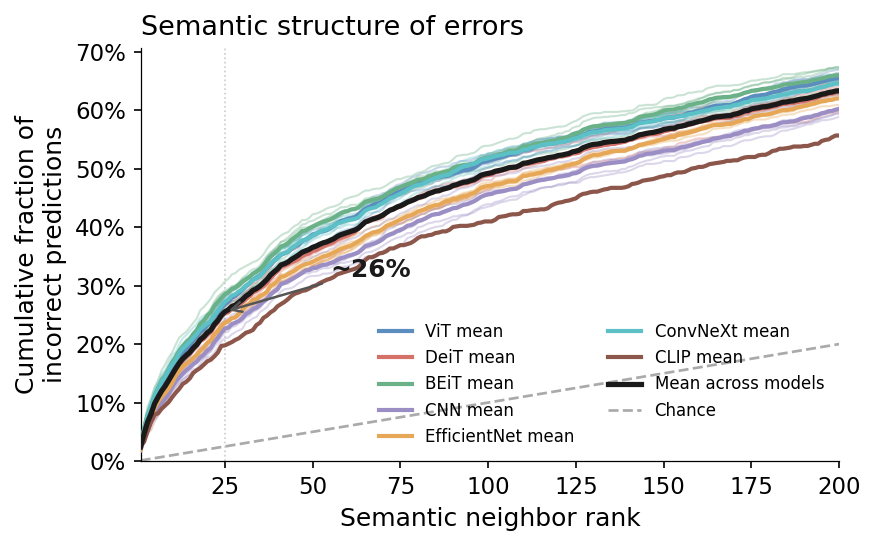

25.6% of the wrong predictions are among the 25 nearest neighbours (chance: 2.5%)


In [9]:
fig = plot_error_ranks(error_ranks, marked_rank=NEIGHBORHOOD)
fig.savefig(FIG_DIR / "error_ranks.pdf")
plt.show()

within = np.mean([np.mean(ranks <= NEIGHBORHOOD) for ranks in error_ranks.values()])
print(f"{within:.1%} of the wrong predictions are among the {NEIGHBORHOOD} nearest neighbours (chance: {NEIGHBORHOOD / 999:.1%})")

### Is this more than chance?

The dashed line assumes that every class is equally likely to be predicted. However, some classes have many close neighbours, and models predict some classes much more often than others.

So we also run a permutation test. We pool the wrong predictions of all models in `MODELS`, shuffle which true class belongs to which prediction, and count again how many predictions land among the nearest neighbours. Repeating this many times tells us what to expect by chance, given the classes the models actually predict. The paper reports this test for all 35 models.

In [10]:
N_PERMUTATIONS = 1000
SEED = 42


def get_fraction_within(true_classes, predicted_classes):
    """Fraction of wrong predictions that lie within the nearest neighbours of the true class."""
    wrong = true_classes != predicted_classes
    return np.mean(NEIGHBOR_RANKS[true_classes[wrong], predicted_classes[wrong]] <= NEIGHBORHOOD)


# Pool the wrong background-only predictions of all models.
predictions = pd.concat([load_predictions(model, "background_only") for model in sorted(MODELS)])
predictions = predictions[predictions["pred_class_idx"] != predictions["true_class_idx"]]
true_classes = predictions["true_class_idx"].values
predicted_classes = predictions["pred_class_idx"].values

# Compare the observed fraction with the fractions after shuffling the true classes.
observed = get_fraction_within(true_classes, predicted_classes)
rng = np.random.RandomState(SEED)
shuffled = np.array([get_fraction_within(rng.permutation(true_classes), predicted_classes) for _ in range(N_PERMUTATIONS)])
p_value = np.mean(shuffled >= observed)

print(f"Observed: {observed:.2%} of {len(predictions):,} wrong predictions are among the {NEIGHBORHOOD} nearest neighbours")
print(f"Shuffled: {shuffled.mean():.2%} on average, so {observed / shuffled.mean():.1f}x more than expected by chance")
print(f"p-value:  {f'{p_value:.3f}' if p_value > 0 else f'< {1 / N_PERMUTATIONS}'} ({N_PERMUTATIONS} permutations)")

Observed: 25.48% of 34,253 wrong predictions are among the 25 nearest neighbours
Shuffled: 2.86% on average, so 8.9x more than expected by chance
p-value:  < 0.001 (1000 permutations)


So even without the object, backgrounds point the models towards the right semantic neighbourhood.

## What else is among the five best guesses?

*Added for the rebuttal: a reviewer asked what the other classes in the top five look like.*

So far, we only looked at the single best guess. But every prediction CSV also holds the four guesses after it. Are those random, or do they also point to the right neighbourhood?

We take every wrong class among the five best guesses of a background-only image and look up its neighbour rank, just like above. We split them by their position in the top five, and also look separately at the images where the true class does not make it into the top five at all.

In [11]:
def get_top5_ranks(model):
    """Neighbour rank of every wrong class among the five best background-only guesses of a model."""
    predictions = load_predictions(model, "background_only")
    rows = []
    for image_id, true_class, guesses in zip(predictions["image_id"], predictions["true_class_idx"], predictions["top5_indices"].apply(json.loads)):
        for slot, guess in enumerate(guesses, start=1):
            if guess != true_class:
                rows.append((model, image_id, slot, guess, NEIGHBOR_RANKS[true_class, guess], true_class in guesses))
    return pd.DataFrame(rows, columns=["model", "image_id", "slot", "predicted_class", "rank", "true_class_in_top5"])


top5_ranks = pd.concat([get_top5_ranks(model) for model in MODELS], ignore_index=True)

Every position in the top five is about ten times more often among the nearest neighbours than chance, not just the best guess. Even when the true class is missing from the top five completely, the guesses still lean towards its neighbourhood.

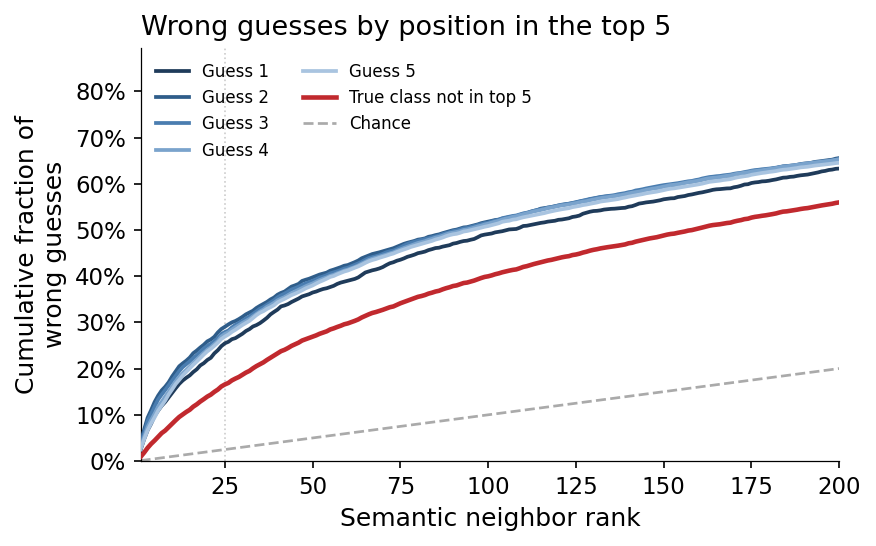

Guess 1: 25.5% among the 25 nearest neighbours
Guess 2: 29.0% among the 25 nearest neighbours
Guess 3: 27.9% among the 25 nearest neighbours
Guess 4: 27.5% among the 25 nearest neighbours
Guess 5: 26.9% among the 25 nearest neighbours
True class not in the top five: 16.6% (chance: 2.5%)


In [12]:
fig = plot_top5_ranks(top5_ranks, marked_rank=NEIGHBORHOOD)
fig.savefig(FIG_DIR / "top5_ranks.pdf")
plt.show()

near = top5_ranks["rank"] <= NEIGHBORHOOD
missing = ~top5_ranks["true_class_in_top5"]
for slot, fraction in near.groupby(top5_ranks["slot"]).mean().items():
    print(f"Guess {slot}: {fraction:.1%} among the {NEIGHBORHOOD} nearest neighbours")
print(f"True class not in the top five: {near[missing].mean():.1%} (chance: {NEIGHBORHOOD / 999:.1%})")

### And the guesses that are far away?

What about the guesses that are not close to the true class? Looking at them per scene type, many of them simply describe the background itself: a lakeside or seashore for water scenes, a valley for mountains, a sliding door or window screen indoors. So they are not random either, the models just name what they see.

The table shows the three most frequent far-away guesses (outside the nearest `NEIGHBORHOOD`) for each background subcategory, with their share of all far-away guesses in that subcategory.

In [13]:
metadata = pd.read_csv(METADATA)
metadata["subcategory"] = metadata["background_subcategory"].fillna(metadata["background_category"])
class_labels = {int(index): label for index, (_, label) in json.loads(CLASS_INDEX.read_text()).items()}

far = top5_ranks[top5_ranks["rank"] > NEIGHBORHOOD].merge(metadata[["image_id", "subcategory"]], on="image_id")


def most_frequent(guesses, n=3):
    """The n most frequent classes with their share, as one line of text."""
    shares = guesses.value_counts(normalize=True).head(n)
    return ", ".join(f"{class_labels[guess]} ({share:.0%})" for guess, share in shares.items())


far.groupby("subcategory")["predicted_class"].apply(most_frequent).to_frame("most frequent far-away guesses")

,most frequent far-away guesses
subcategory,
bed_sofa,"quilt (11%), studio_couch (10%), pillow (6%)"
field,"worm_fence (7%), megalith (3%), lakeside (3%)"
floor,"doormat (4%), patio (4%), sliding_door (3%)"
forest,"lakeside (8%), valley (6%), mountain_bike (4%)"
ground,"partridge (4%), worm_fence (2%), whiptail (2%)"
hall,"sliding_door (6%), stage (4%), cinema (4%)"
human,"Band_Aid (5%), jersey (2%), sunscreen (2%)"
inside_house,"sliding_door (10%), window_screen (5%), wardro..."
misc,"window_screen (2%), crate (2%), window_shade (2%)"


## Putting it together

The figure for the paper combines the three main results of this notebook side by side: (a) the object-only accuracy (averaged over black, white and pink noise), (b) the background-only accuracy, and (c) how close the wrong background-only predictions are to the true class. As in the paper, it always shows the six `MAIN_MODELS`, whatever `MODELS` is set to (with all 35 models it would become far too wide; use the three single figures above for those). `TOP_K` is the same as above.

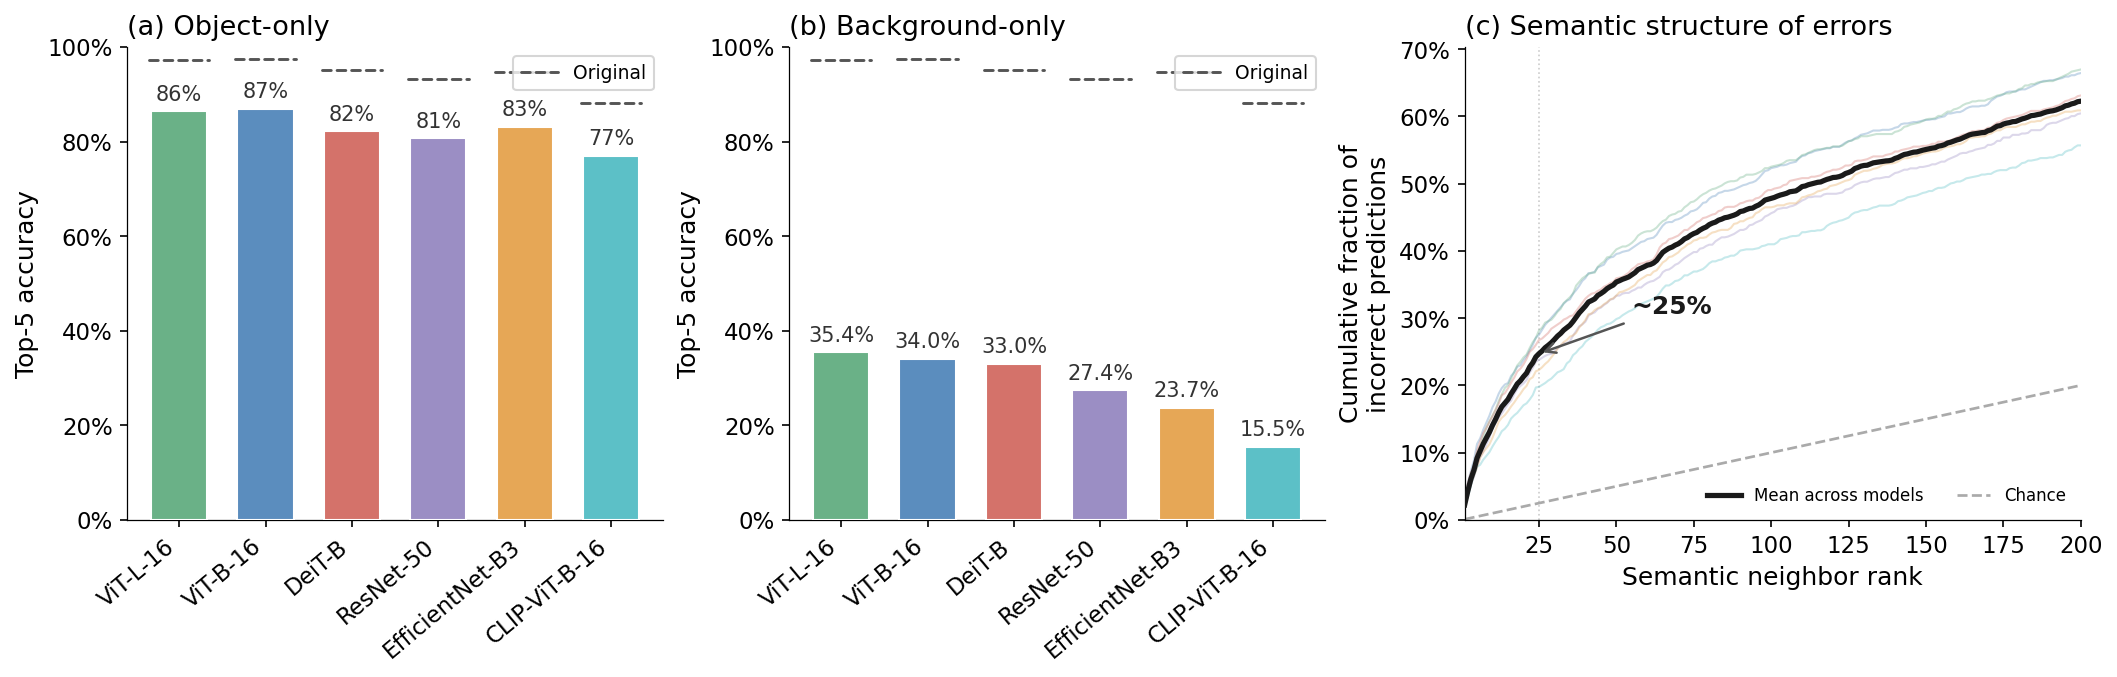

In [14]:
# The paper figure always shows the six main models.
main_accuracy = get_accuracy_table(MAIN_MODELS, TOP_K)
main_error_ranks = {model: get_error_ranks(model) for model in MAIN_MODELS}

fig = plot_controls_overview(main_accuracy, main_error_ranks, TOP_K, marked_rank=NEIGHBORHOOD, order=get_accuracy_table(MAIN_MODELS, top_k=1))
fig.savefig(FIG_DIR / "controls_overview.pdf")
plt.show()


The second figure puts the two analyses of the wrong background-only guesses next to each other: (a) the wrong top-1 predictions, as in the section "Background predictions are not random", and (b) the wrong guesses by their position in the top five. Unlike the figure above, it uses `MODELS`, like the two sections it comes from.

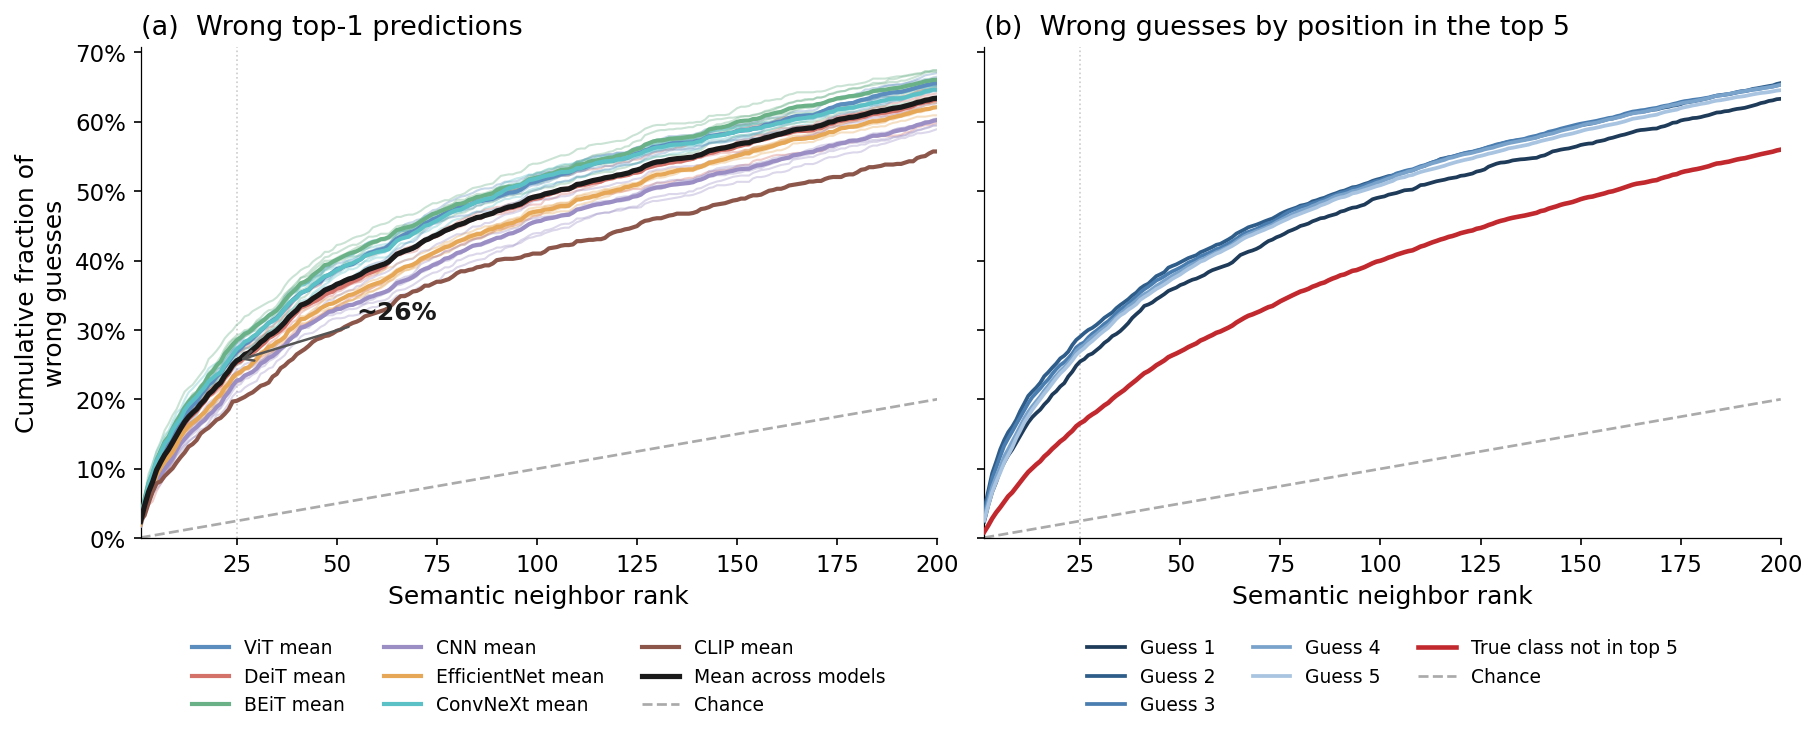

In [15]:
fig = plot_error_structure(error_ranks, top5_ranks, marked_rank=NEIGHBORHOOD)
fig.savefig(FIG_DIR / "error_structure.pdf")
plt.show()